# Disaster Tweets — Exploratory Data Analysis

This analysis uses **train.csv only**. Target 1 is interpreted as disaster-related
and target 0 as non-disaster. All findings are descriptive of this labeled sample;
they are not estimates of model performance or real-world disaster prevalence.
The original CSV is never modified. Run `python scripts/eda.py` from this directory,
or open `eda_train.ipynb` to inspect the executed analysis section by section.

In [1]:
from pathlib import Path
from disaster_tweets.paths import PROJECT_ROOT, RAW_DATA_DIR, PROCESSED_DATA_DIR, EDA_REPORTS_DIR, BASELINE_REPORTS_DIR
from urllib.parse import unquote
import hashlib
import html
import json
import re
import unicodedata

import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from sklearn.feature_extraction.text import CountVectorizer
from disaster_tweets.preprocessing import clean_metadata, read_training_csv, MISSING_TOKEN

ROOT = PROJECT_ROOT
OUT = EDA_REPORTS_DIR
FIG = OUT / 'figures'
TABLE = OUT / 'tables'
FIG.mkdir(parents=True, exist_ok=True)
TABLE.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_colwidth', 100)
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})
COLORS = ['#59718C', '#D86547']
LABELS = {0: 'Non-disaster', 1: 'Disaster'}
df = pd.read_csv(RAW_DATA_DIR / 'train.csv', dtype={'keyword': 'string', 'location': 'string', 'text': 'string'})
original_columns = df.columns.tolist()
assert set(original_columns) == {'id', 'keyword', 'location', 'text', 'target'}
assert df['text'].notna().all() and df['target'].isin([0, 1]).all()

def save_table(name, frame, index=False):
    frame.to_csv(TABLE / f'{name}.csv', index=index)
    return frame

def save_figure(name, fig):
    fig.tight_layout()
    fig.savefig(FIG / f'{name}.png', bbox_inches='tight')
    display(Image(filename=str(FIG / f'{name}.png')))
    plt.close(fig)

print(f'{len(df):,} rows × {len(original_columns)} columns')
print('Raw input preview — missing metadata is intentionally shown before cleaning:')
display(df.head())

7,613 rows × 5 columns
Raw input preview — missing metadata is intentionally shown before cleaning:


,id,keyword,location,text,target
0,1,<NA>,<NA>,Our Deeds are the Reason of this #earthquake May ALLAH Forgive us all,1
1,4,<NA>,<NA>,Forest fire near La Ronge Sask. Canada,1
2,5,<NA>,<NA>,All residents asked to 'shelter in place' are being notified by officers. No other evacuation or...,1
3,6,<NA>,<NA>,"13,000 people receive #wildfires evacuation orders in California",1
4,7,<NA>,<NA>,Just got sent this photo from Ruby #Alaska as smoke from #wildfires pours into a school,1


## 1. Schema, completeness, and target balance

Blank or whitespace-only strings count as missing in the completeness table.
IDs are identifiers, not semantic input features. The majority-class accuracy
below is only a reference; it is not a trained or validated model score.

,column,dtype,missing_count,missing_pct,unique_non_null
0,id,int64,0,0.00,7613
1,keyword,string,61,0.80,221
2,location,string,2534,33.29,3341
3,text,string,0,0.00,7503
4,target,int64,0,0.00,2


,target,count,label,percent
0,0,4342,Non-disaster,57.03
1,1,3271,Disaster,42.97


Duplicate IDs: 0
Exact duplicate full rows: 0
Majority-class accuracy reference: 57.03%


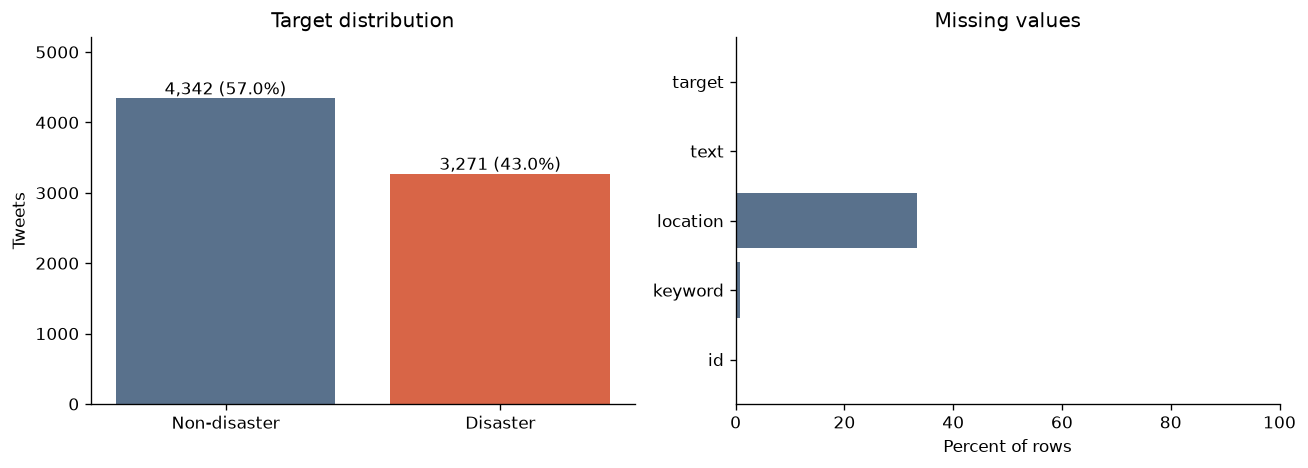

In [2]:
missing = df.isna() | df.astype('string').apply(lambda s: s.str.strip().eq('')).fillna(False)
schema = pd.DataFrame({'column': original_columns,
                       'dtype': [str(df[c].dtype) for c in original_columns],
                       'missing_count': [int(missing[c].sum()) for c in original_columns],
                       'missing_pct': [100 * missing[c].mean() for c in original_columns],
                       'unique_non_null': [df[c].nunique() for c in original_columns]})
save_table('schema', schema)
display(schema.round(2))
classes = df['target'].value_counts().sort_index().rename_axis('target').reset_index(name='count')
classes['label'] = classes['target'].map(LABELS)
classes['percent'] = 100 * classes['count'] / len(df)
save_table('class_distribution', classes)
display(classes.round(2))
print('Duplicate IDs:', df['id'].duplicated().sum())
print('Exact duplicate full rows:', df[original_columns].duplicated().sum())
print(f'Majority-class accuracy reference: {classes["percent"].max():.2f}%')
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
bars = axes[0].bar(classes['label'], classes['count'], color=COLORS)
axes[0].bar_label(bars, labels=[f'{n:,} ({p:.1f}%)' for n, p in zip(classes['count'], classes['percent'])])
axes[0].set(title='Target distribution', ylabel='Tweets', ylim=(0, classes['count'].max() * 1.2))
axes[1].barh(schema['column'], schema['missing_pct'], color='#59718C')
axes[1].set(title='Missing values', xlabel='Percent of rows', xlim=(0, 100))
save_figure('01_overview', fig)

### 1.1 Apply the missing-value policy

Keep every row and leave text, ID, and target unchanged. Trim keyword/location
values and replace empty, whitespace-only, or null metadata with `__MISSING__`.
This marker represents unknown information; it does not recover a real value.
We do not fill with the most frequent keyword or location. The processed copy
is saved separately as `train_processed.csv`; all EDA statistics below still
describe the original input. Model comparisons are in `baseline_train.ipynb`.

In [3]:
raw_for_cleaning = read_training_csv(RAW_DATA_DIR / 'train.csv')
train_processed = clean_metadata(raw_for_cleaning)
assert len(train_processed) == len(raw_for_cleaning)
pd.testing.assert_frame_equal(train_processed[['id', 'text', 'target']], raw_for_cleaning[['id', 'text', 'target']])
assert train_processed[['keyword', 'location']].notna().all().all()
assert train_processed[['keyword', 'location']].ne('').all().all()
train_processed.to_csv(PROCESSED_DATA_DIR / 'train_processed.csv', index=False)
cleaning_audit = pd.DataFrame({
    'column': ['keyword', 'location'],
    'missing_before': [int(raw_for_cleaning[c].str.strip().eq('').sum()) for c in ['keyword', 'location']],
    'missing_after': [int(train_processed[c].isna().sum()) for c in ['keyword', 'location']],
    'missing_marker_count': [int(train_processed[c].eq(MISSING_TOKEN).sum()) for c in ['keyword', 'location']],
})
save_table('missing_value_handling', cleaning_audit)
display(cleaning_audit)
print('Processed preview — missing metadata has explicit markers:')
display(train_processed.head())
print(f'Saved train_processed.csv with {len(train_processed):,} rows; raw text and labels are unchanged.')

,column,missing_before,missing_after,missing_marker_count
0,keyword,61,0,61
1,location,2534,0,2534


Processed preview — missing metadata has explicit markers:


,id,keyword,location,text,target
0,1,__MISSING__,__MISSING__,Our Deeds are the Reason of this #earthquake May ALLAH Forgive us all,1
1,4,__MISSING__,__MISSING__,Forest fire near La Ronge Sask. Canada,1
2,5,__MISSING__,__MISSING__,All residents asked to 'shelter in place' are being notified by officers. No other evacuation or...,1
3,6,__MISSING__,__MISSING__,"13,000 people receive #wildfires evacuation orders in California",1
4,7,__MISSING__,__MISSING__,Just got sent this photo from Ruby #Alaska as smoke from #wildfires pours into a school,1


Saved train_processed.csv with 7,613 rows; raw text and labels are unchanged.


## 2. Duplicate tweets and conflicting labels

Three matching rules are compared: exact text; conservative normalization
(HTML unescape, Unicode NFKC, case folding, whitespace collapse); and template
normalization (also replaces URLs and @mentions). Template matches are **review
candidates**, since these replacements can merge tweets about different events.
A conflict means that the same matching key occurs with both target values.
Do not automatically relabel or delete these examples.

In [4]:
def normalize_text(value):
    return re.sub(r'\s+', ' ', unicodedata.normalize('NFKC', html.unescape(value)).casefold()).strip()

def template_text(value):
    value = re.sub(r'https?://\S+|www\.\S+', ' <url> ', value, flags=re.I)
    value = re.sub(r'(?<!\w)@\w+', ' <user> ', value)
    return normalize_text(value)

df['normalized_text'] = df['text'].map(normalize_text)
df['template_text'] = df['text'].map(template_text)
duplicate_stats = []
for key in ['text', 'normalized_text', 'template_text']:
    groups = df.groupby(key).agg(rows=('id', 'size'), labels=('target', 'nunique'))
    duplicates = groups[groups['rows'] > 1]
    conflicts = groups[groups['labels'] > 1]
    duplicate_stats.append({'matching_rule': key, 'duplicate_groups': len(duplicates),
                            'rows_in_duplicate_groups': int(duplicates['rows'].sum()),
                            'excess_duplicate_rows': int((duplicates['rows'] - 1).sum()),
                            'conflicting_groups': len(conflicts),
                            'rows_in_conflicting_groups': int(conflicts['rows'].sum())})
duplicate_stats = save_table('duplicate_summary', pd.DataFrame(duplicate_stats))
display(duplicate_stats)
conflicting_texts = df.groupby('text')['target'].nunique().loc[lambda s: s > 1].index
conflict_rows = df.loc[df['text'].isin(conflicting_texts), original_columns].sort_values(['text', 'target', 'id'])
save_table('exact_label_conflicts', conflict_rows)
conflict_examples = (conflict_rows.groupby('text').agg(rows=('id', 'size'),
                    target_0=('target', lambda x: int((x == 0).sum())),
                    target_1=('target', lambda x: int((x == 1).sum()))))
display(conflict_examples.head(8))

,matching_rule,duplicate_groups,rows_in_duplicate_groups,excess_duplicate_rows,conflicting_groups,rows_in_conflicting_groups
0,text,69,179,110,18,55
1,normalized_text,70,182,112,18,56
2,template_text,305,974,669,69,245


,rows,target_0,target_1
text,,,
#Allah describes piling up #wealth thinking it would last #forever as the description of the people of #Hellfire in Surah Humaza. #Reflect,3,2,1
#foodscare #offers2go #NestleIndia slips into loss after #Magginoodle #ban unsafe and hazardous for #humanconsumption,3,1,2
.POTUS #StrategicPatience is a strategy for #Genocide; refugees; IDP Internally displaced people; horror; etc. https://t.co/rqWuoy1fm4,4,1,3
CLEARED:incident with injury:I-495 inner loop Exit 31 - MD 97/Georgia Ave Silver Spring,3,1,2
Caution: breathing may be hazardous to your health.,2,1,1
He came to a land which was engulfed in tribal war and turned it into a land of peace i.e. Madinah. #ProphetMuhammad #islam,6,4,2
Hellfire is surrounded by desires so be careful and donÛªt let your desires control you! #Afterlife,3,2,1
Hellfire! We donÛªt even want to think about it or mention it so letÛªs not do anything that leads to it #islam!,2,1,1


## 3. Tweet length and surface features

Character length uses the original string, including URLs. Word count is a
whitespace split, not a language model's tokenizer. URL, hashtag, mention, and
non-ASCII indicators use simple regular expressions, so treat them as proxies.
Uppercase ratio counts uppercase letters divided by alphabetic characters.
These are associations, not causal effects or proven predictive gains.

char_count                        word_count                     
             mean median    std min  max       mean median   std min max
target                                                                  
0           95.71  101.0  35.89   7  157      14.70   15.0  6.16   1  31
1          108.11  115.0  29.31  14  151      15.17   15.0  5.10   2  30

,char_count,word_count
0.00,7.0,1.0
0.25,78.0,11.0
0.50,107.0,15.0
0.75,133.0,19.0
0.90,138.0,22.0
0.95,140.0,24.0
0.99,143.0,27.0
1.00,157.0,31.0


target,0,1
feature,,
Contains URL,41.43,66.40
Contains exclamation,12.05,5.99
Contains hashtag,20.29,26.05
Contains mention,30.82,20.06
Contains non-ASCII,8.01,10.67
Contains question,17.27,8.93
Keyword missing,0.44,1.28
Location missing,33.58,32.90


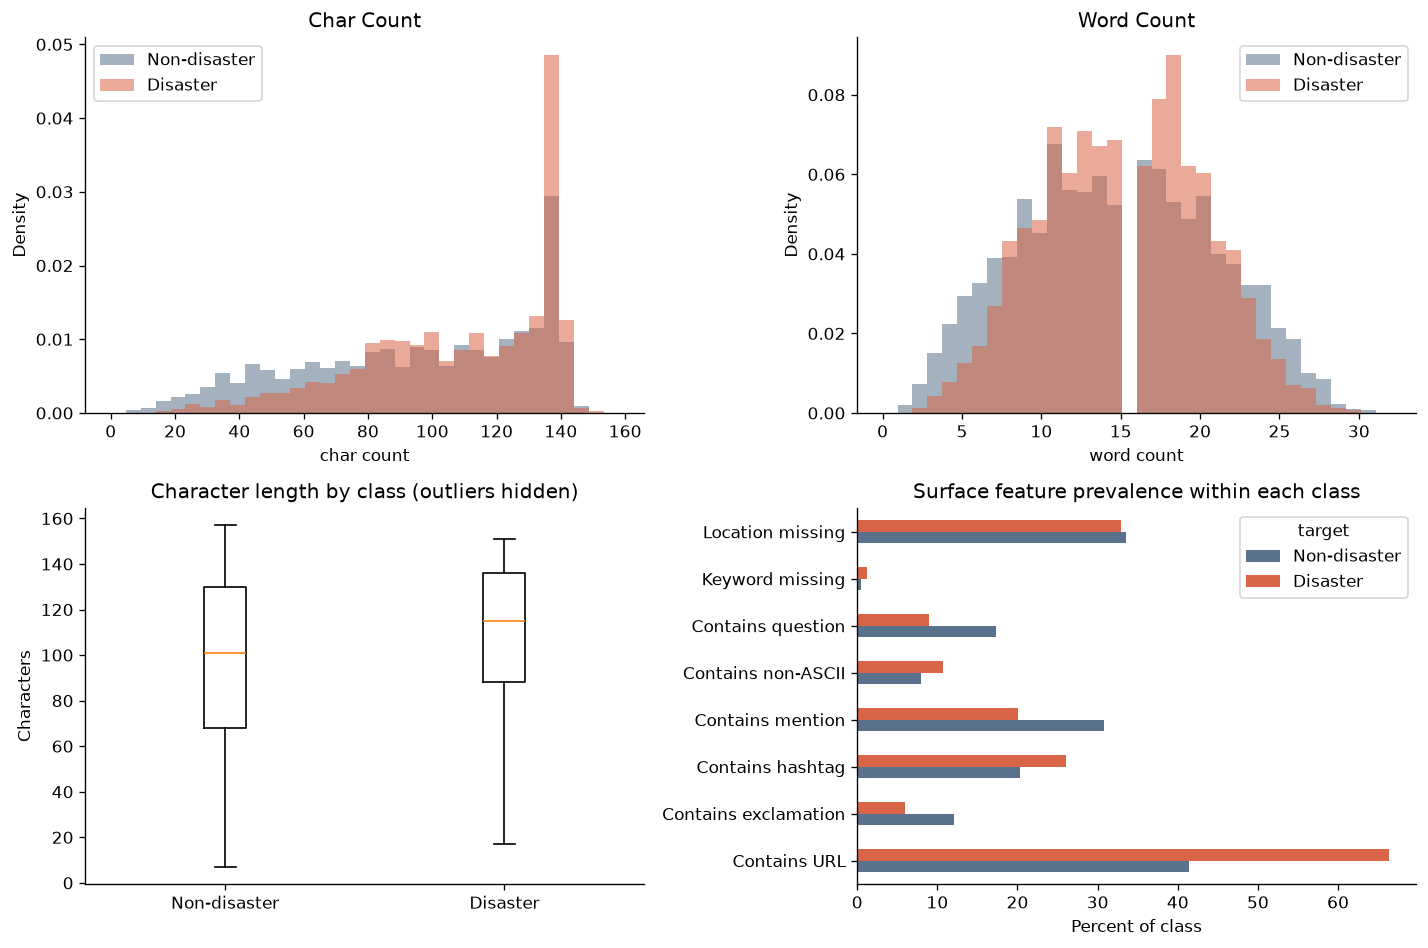

,id,keyword,location,text,target,char_count,word_count
1882,2703,crushed,<NA>,Crushed,0,7,1
4890,6962,massacre,<NA>,Bad day,0,7,2
5115,7295,nuclear%20reactor,<NA>,Err:509,0,7,1
24,36,<NA>,<NA>,LOOOOOOL,0,8,1
30,44,<NA>,<NA>,The end!,0,8,2
3670,5224,fatality,Rafael castillo,fatality,0,8,1
4971,7088,meltdown,<NA>,Meltdown,0,8,1
28,40,<NA>,<NA>,Cooool :),0,9,2
3667,5221,fatality,Nairobi,Fatality!,0,9,1
3749,5326,fire,<NA>,I See Fire,0,10,3


In [5]:
text = df['text']
df['char_count'] = text.str.len()
df['word_count'] = text.str.split().str.len()
df['url_count'] = text.str.count(r'(?i)https?://\S+|www\.\S+')
df['hashtag_count'] = text.str.count(r'(?<!\w)#\w+')
df['mention_count'] = text.str.count(r'(?<!\w)@\w+')
df['exclamation_count'] = text.str.count('!')
df['question_count'] = text.str.count(r'\?')
df['uppercase_ratio'] = text.map(lambda s: sum(c.isupper() for c in s) / max(1, sum(c.isalpha() for c in s)))
df['has_non_ascii'] = text.map(lambda s: any(ord(c) > 127 for c in s))
numeric_features = ['char_count', 'word_count', 'url_count', 'hashtag_count',
                    'mention_count', 'exclamation_count', 'question_count', 'uppercase_ratio']
length_summary = df.groupby('target')[['char_count', 'word_count']].agg(['mean', 'median', 'std', 'min', 'max'])
save_table('length_summary', length_summary, index=True)
display(length_summary.round(2))
quantiles = df[['char_count', 'word_count']].quantile([0, .25, .5, .75, .90, .95, .99, 1])
save_table('length_quantiles', quantiles, index=True)
display(quantiles)
feature_rates = []
for feature, present in {
    'Contains URL': df['url_count'] > 0,
    'Contains hashtag': df['hashtag_count'] > 0,
    'Contains mention': df['mention_count'] > 0,
    'Contains exclamation': df['exclamation_count'] > 0,
    'Contains question': df['question_count'] > 0,
    'Contains non-ASCII': df['has_non_ascii'],
    'Keyword missing': missing['keyword'],
    'Location missing': missing['location'],
}.items():
    for target in [0, 1]:
        mask = df['target'].eq(target)
        feature_rates.append({'feature': feature, 'target': target,
                              'class_size': int(mask.sum()),
                              'present_count': int(present[mask].sum()),
                              'present_pct': float(100 * present[mask].mean())})
feature_rates = save_table('surface_feature_rates', pd.DataFrame(feature_rates))
display(feature_rates.pivot(index='feature', columns='target', values='present_pct').round(2))
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, feature in zip(axes[0], ['char_count', 'word_count']):
    bins = np.linspace(0, df[feature].max() + 1, 35)
    for target, color in enumerate(COLORS):
        ax.hist(df.loc[df['target'] == target, feature], bins=bins, density=True,
                alpha=.55, label=LABELS[target], color=color)
    ax.set(title=feature.replace('_', ' ').title(), xlabel=feature.replace('_', ' '), ylabel='Density')
    ax.legend()
axes[1, 0].boxplot([df.loc[df['target'] == t, 'char_count'] for t in [0, 1]],
                  tick_labels=[LABELS[t] for t in [0, 1]], showfliers=False)
axes[1, 0].set(title='Character length by class (outliers hidden)', ylabel='Characters')
feature_rates.pivot(index='feature', columns='target', values='present_pct').rename(columns=LABELS).plot.barh(
    ax=axes[1, 1], color=COLORS)
axes[1, 1].set(title='Surface feature prevalence within each class', xlabel='Percent of class', ylabel='')
save_figure('02_text_features', fig)
save_table('longest_tweets', df.nlargest(15, 'char_count')[original_columns + ['char_count', 'word_count']])
save_table('shortest_tweets', df.nsmallest(15, 'char_count')[original_columns + ['char_count', 'word_count']])

## 4. Keywords and location metadata

Keyword labels are URL-decoded for readability (for example, `body%20bags`).
Keyword disaster rates are reported with counts and 95% Wilson intervals to
show sampling uncertainty. Charts restrict to at least 20 rows per keyword;
these are descriptive intervals, with no adjustment for multiple comparisons
or dependence between duplicate tweets. Location is free-form user text and
cannot be interpreted as a verified event location.

,keyword,count,disaster_count,disaster_rate,wilson_low,wilson_high
71,derailment,39,39,1.000,0.910,1.000
220,wreckage,39,39,1.000,0.910,1.000
63,debris,37,37,1.000,0.906,1.000
154,outbreak,40,39,0.975,0.871,0.996
153,oil spill,38,37,0.974,0.865,0.995
206,typhoon,38,37,0.974,0.865,0.995
188,suicide bombing,33,32,0.970,0.847,0.995
187,suicide bomber,31,30,0.968,0.838,0.994
33,bombing,29,27,0.931,0.780,0.981
167,rescuers,35,32,0.914,0.776,0.970


,keyword,count,disaster_count,disaster_rate,wilson_low,wilson_high
3,aftershock,34,0,0.000,0.000,0.102
30,body bags,41,1,0.024,0.004,0.126
171,ruin,37,1,0.027,0.005,0.138
20,blazing,34,1,0.029,0.005,0.149
28,body bag,33,1,0.030,0.005,0.153
89,electrocute,32,1,0.031,0.006,0.157
174,screaming,36,2,0.056,0.015,0.181
202,traumatised,35,2,0.057,0.016,0.186
22,blew up,33,2,0.061,0.017,0.196
157,panicking,33,2,0.061,0.017,0.196


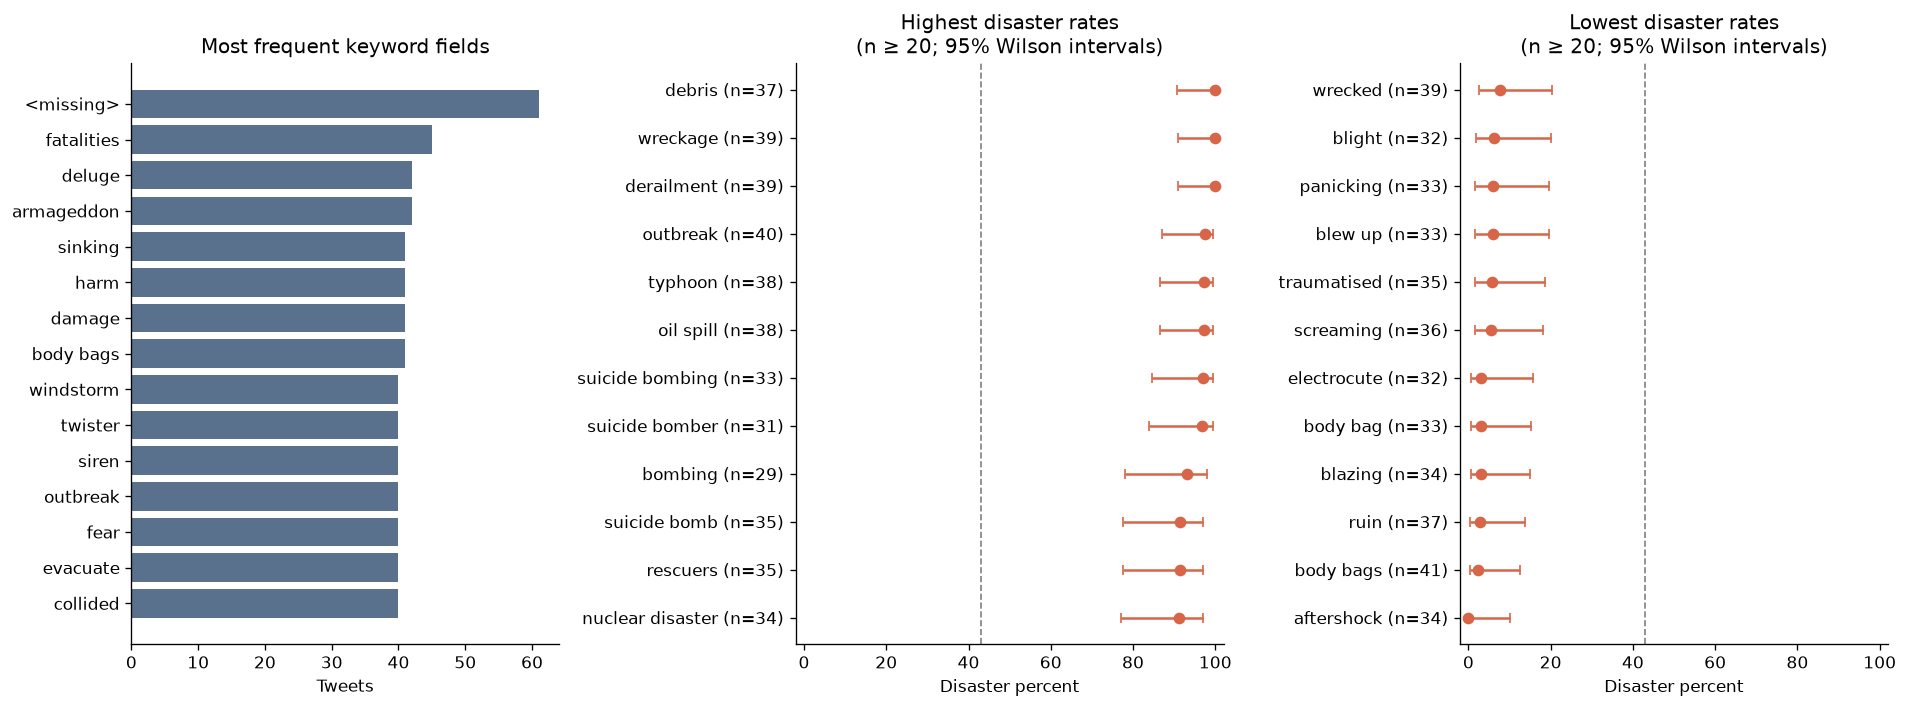

,location,count,disaster_rate
0,USA,104,0.644
1,New York,71,0.225
2,United States,50,0.540
3,London,45,0.356
4,Canada,29,0.448
5,Nigeria,28,0.786
6,UK,27,0.593
7,"Los Angeles, CA",26,0.308
8,India,24,0.833
9,Mumbai,22,0.864


,field,is_missing,count,disaster_rate
0,keyword,False,7552,0.428
1,keyword,True,61,0.689
2,location,False,5079,0.432
3,location,True,2534,0.425


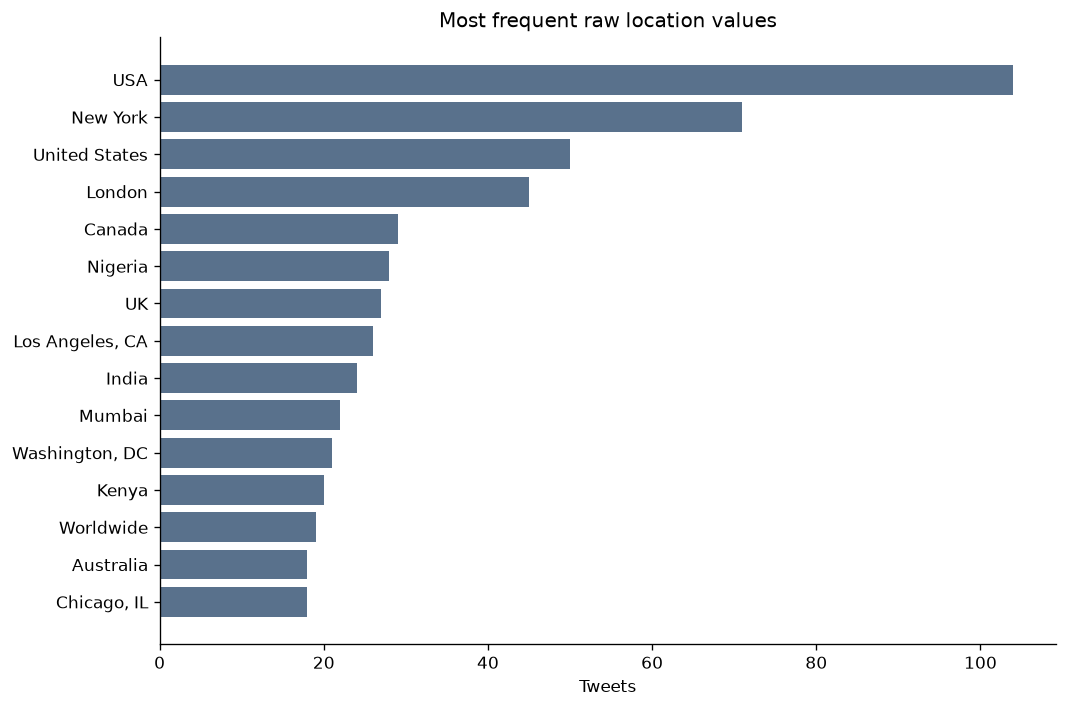

In [6]:
df['keyword_clean'] = df['keyword'].map(lambda x: unquote(x) if pd.notna(x) else '<missing>')
keywords = (df.groupby('keyword_clean').agg(count=('id', 'size'), disaster_count=('target', 'sum'))
            .reset_index().rename(columns={'keyword_clean': 'keyword'}))
keywords['disaster_rate'] = keywords['disaster_count'] / keywords['count']
z = 1.96
n, p = keywords['count'], keywords['disaster_rate']
center = (p + z*z/(2*n)) / (1 + z*z/n)
half = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n)) / (1 + z*z/n)
keywords['wilson_low'] = center - half
keywords['wilson_high'] = center + half
save_table('keyword_statistics', keywords.sort_values(['count', 'keyword'], ascending=[False, True]))
eligible = keywords[(keywords['count'] >= 20) & keywords['keyword'].ne('<missing>')]
display(eligible.sort_values(['disaster_rate', 'count'], ascending=[False, False]).head(12).round(3))
display(eligible.sort_values(['disaster_rate', 'count'], ascending=[True, False]).head(12).round(3))
fig, axes = plt.subplots(1, 3, figsize=(16, 6))
top_counts = keywords.nlargest(15, 'count').sort_values('count')
axes[0].barh(top_counts['keyword'], top_counts['count'], color=COLORS[0])
axes[0].set(title='Most frequent keyword fields', xlabel='Tweets')
for ax, ascending, title in [(axes[1], False, 'Highest disaster rates'), (axes[2], True, 'Lowest disaster rates')]:
    subset = eligible.sort_values(['disaster_rate', 'count'], ascending=[ascending, False]).head(12).sort_values('disaster_rate')
    y = np.arange(len(subset))
    ax.errorbar(100*subset['disaster_rate'], y,
                xerr=np.array([100*(subset['disaster_rate'] - subset['wilson_low']),
                               100*(subset['wilson_high'] - subset['disaster_rate'])]).clip(min=0),
                fmt='o', color=COLORS[1], capsize=3)
    ax.set(yticks=y, yticklabels=[f'{k} (n={c})' for k, c in zip(subset['keyword'], subset['count'])],
           title=title + '\n(n ≥ 20; 95% Wilson intervals)', xlabel='Disaster percent', xlim=(-2, 102))
    ax.axvline(100*df['target'].mean(), color='grey', linestyle='--', linewidth=1)
save_figure('03_keywords', fig)

locations = (df.dropna(subset=['location']).groupby('location')
             .agg(count=('id', 'size'), disaster_rate=('target', 'mean'))
             .sort_values('count', ascending=False).reset_index())
save_table('location_statistics', locations)
display(locations.head(15).round(3))
metadata_missingness = []
for column in ['keyword', 'location']:
    for is_missing in [False, True]:
        subset = df[missing[column] == is_missing]
        metadata_missingness.append({'field': column, 'is_missing': is_missing,
                                     'count': len(subset), 'disaster_rate': subset['target'].mean()})
save_table('metadata_missingness', pd.DataFrame(metadata_missingness))
display(pd.DataFrame(metadata_missingness).round(3))
fig, ax = plt.subplots(figsize=(9, 6))
subset = locations.head(15).sort_values('count')
ax.barh(subset['location'], subset['count'], color=COLORS[0])
ax.set(title='Most frequent raw location values', xlabel='Tweets')
save_figure('04_locations', fig)

## 5. Words and bigrams by class

Analysis-only normalization removes URLs and @mentions, lowercases text, and
tokenizes alphabetic words of at least two characters. A fixed English stopword
list is used for these visualizations only. Counts are **document frequencies**:
a word or bigram contributes at most once per tweet. The comparison reports
class-normalized prevalence and smoothed log2 prevalence ratios. It is not a
significance test. Min document frequency is 20 for words and 10 for bigrams.
Duplicates are retained here, so repeated news templates can dominate patterns.

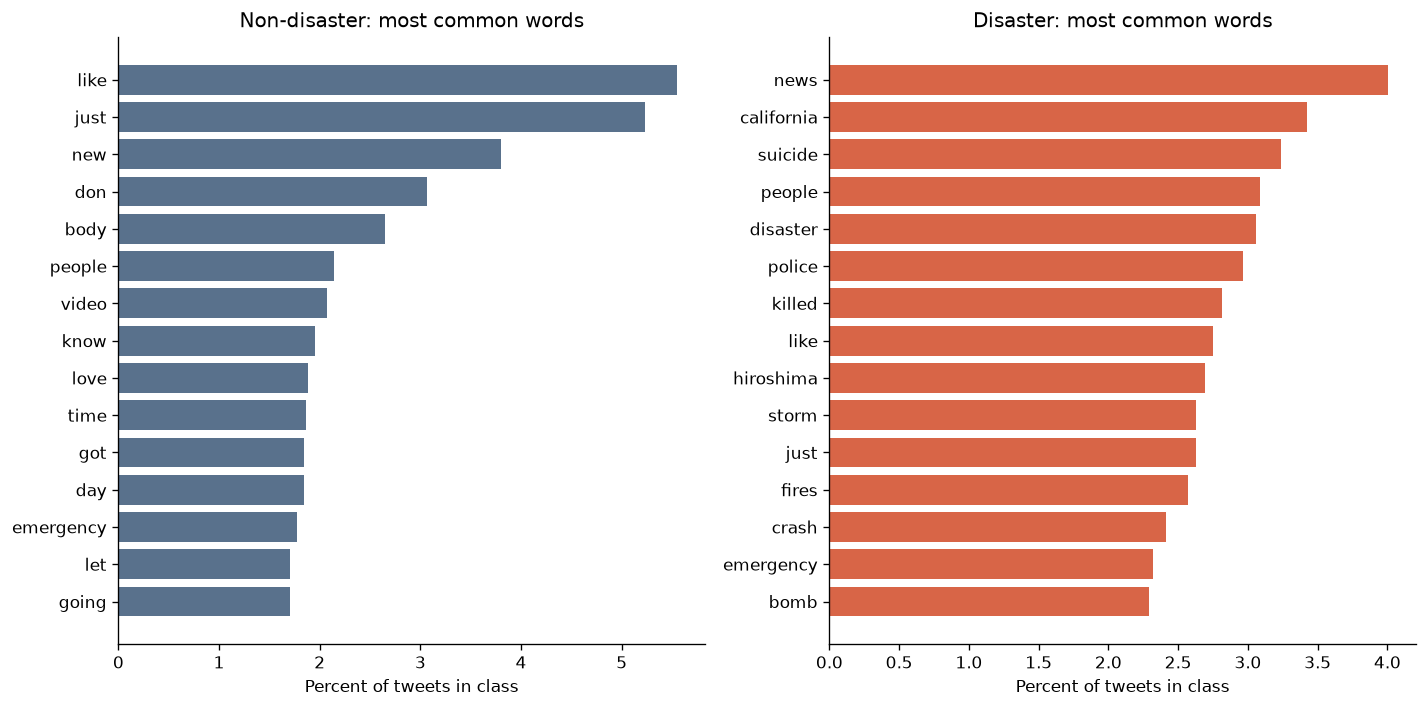

Words: strongest positive associations with disaster labels


,term,documents_target_0,documents_target_1,percent_target_0,percent_target_1,total_documents,log2_prevalence_ratio_disaster
397,northern,0,64,0.000,1.957,64,7.420
146,debris,0,49,0.000,1.498,49,7.038
508,severe,0,44,0.000,1.345,44,6.884
155,derailment,0,40,0.000,1.223,40,6.748
330,legionnaires,0,39,0.000,1.192,39,6.712
303,investigators,0,37,0.000,1.131,37,6.637
372,migrants,0,37,0.000,1.131,37,6.637
379,mosque,0,32,0.000,0.978,32,6.431
162,detonated,0,31,0.000,0.948,31,6.386
432,pkk,0,31,0.000,0.948,31,6.386


Words: strongest negative associations with disaster labels


,term,documents_target_0,documents_target_1,percent_target_0,percent_target_1,total_documents,log2_prevalence_ratio_disaster
37,bags,39,1,0.898,0.031,40,-4.310
35,bag,38,1,0.875,0.031,39,-4.273
481,ruin,37,1,0.852,0.031,38,-4.235
184,ebay,29,1,0.668,0.031,30,-3.889
186,electrocute,28,1,0.645,0.031,29,-3.839
327,leather,21,1,0.484,0.031,22,-3.433
38,ball,20,1,0.461,0.031,21,-3.364
367,mayhem,19,1,0.438,0.031,20,-3.292
57,blew,32,2,0.737,0.061,34,-3.292
420,panicking,31,2,0.714,0.061,33,-3.247


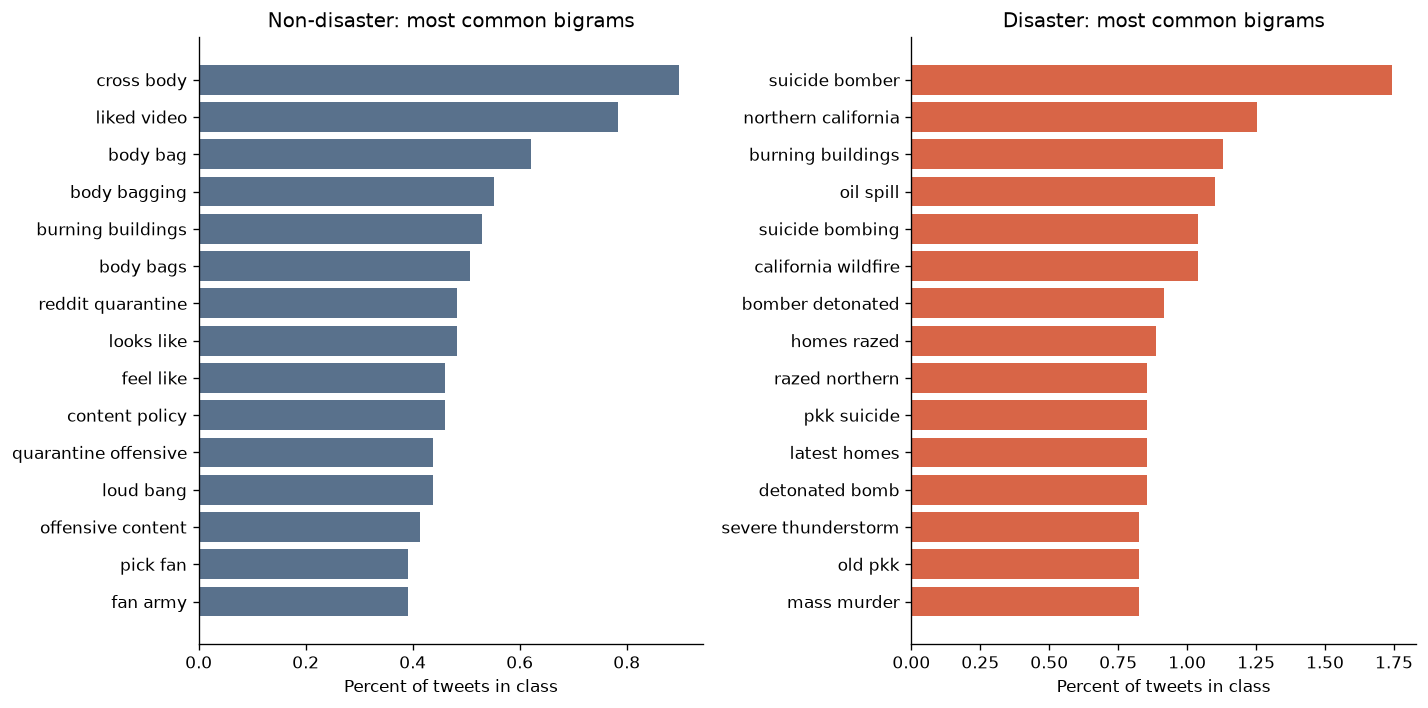

Bigrams: strongest positive associations with disaster labels


,term,documents_target_0,documents_target_1,percent_target_0,percent_target_1,total_documents,log2_prevalence_ratio_disaster
270,suicide bomber,0,57,0.0,1.743,57,7.254
187,northern california,0,41,0.0,1.253,41,6.784
45,california wildfire,0,34,0.0,1.039,34,6.517
36,bomber detonated,0,30,0.0,0.917,30,6.339
125,homes razed,0,29,0.0,0.887,29,6.291
74,detonated bomb,0,28,0.0,0.856,28,6.241
149,latest homes,0,28,0.0,0.856,28,6.241
212,pkk suicide,0,28,0.0,0.856,28,6.241
225,razed northern,0,28,0.0,0.856,28,6.241
199,old pkk,0,27,0.0,0.825,27,6.190


Bigrams: strongest negative associations with disaster labels


,term,documents_target_0,documents_target_1,percent_target_0,percent_target_1,total_documents,log2_prevalence_ratio_disaster
64,cross body,39,1,0.898,0.031,40,-4.310
207,pay pile,10,0,0.230,0.000,10,-3.984
32,body bag,27,1,0.622,0.031,28,-3.788
34,body bags,22,1,0.507,0.031,23,-3.498
96,fan army,17,1,0.392,0.031,18,-3.136
210,pick fan,17,1,0.392,0.031,18,-3.136
226,read ebay,15,1,0.345,0.031,16,-2.961
81,don let,13,1,0.299,0.031,14,-2.761
99,faux leather,12,1,0.276,0.031,13,-2.650
223,quarantine offensive,19,2,0.438,0.061,21,-2.555


In [7]:
lexical_text = text.map(lambda s: re.sub(r'(?<!\w)@\w+', ' ', re.sub(r'https?://\S+|www\.\S+', ' ', html.unescape(s), flags=re.I)))
lexical_tables = {}
for name, ngram_range, minimum in [('words', (1, 1), 20), ('bigrams', (2, 2), 10)]:
    vectorizer = CountVectorizer(lowercase=True, stop_words='english',
                                token_pattern=r'(?u)\b[a-zA-Z]{2,}\b',
                                ngram_range=ngram_range, binary=True, min_df=minimum)
    matrix = vectorizer.fit_transform(lexical_text)
    frequencies = {t: np.asarray(matrix[df['target'].to_numpy() == t].sum(axis=0)).ravel() for t in [0, 1]}
    sizes = {t: int(df['target'].eq(t).sum()) for t in [0, 1]}
    table = pd.DataFrame({'term': vectorizer.get_feature_names_out(),
                          'documents_target_0': frequencies[0], 'documents_target_1': frequencies[1]})
    for t in [0, 1]:
        table[f'percent_target_{t}'] = 100 * frequencies[t] / sizes[t]
    table['total_documents'] = frequencies[0] + frequencies[1]
    table['log2_prevalence_ratio_disaster'] = np.log2(((frequencies[1] + .5)/(sizes[1]+1)) / ((frequencies[0]+.5)/(sizes[0]+1)))
    lexical_tables[name] = table
    save_table(f'{name}_document_frequencies', table.sort_values('total_documents', ascending=False))
    fig, axes = plt.subplots(1, 2, figsize=(12, 6))
    for target, ax, color in zip([0, 1], axes, COLORS):
        subset = table.nlargest(15, f'percent_target_{target}').sort_values(f'percent_target_{target}')
        ax.barh(subset['term'], subset[f'percent_target_{target}'], color=color)
        ax.set(title=f'{LABELS[target]}: most common {name}', xlabel='Percent of tweets in class')
    save_figure('05_' + name, fig)
    print(f'{name.title()}: strongest positive associations with disaster labels')
    display(table.nlargest(12, 'log2_prevalence_ratio_disaster').round(3))
    print(f'{name.title()}: strongest negative associations with disaster labels')
    display(table.nsmallest(12, 'log2_prevalence_ratio_disaster').round(3))

## 6. Row order and validation design

Contiguous slices are examined because row order can group similar topics.
Neither ID nor row position is a timestamp. Class balance alone cannot detect
duplicate leakage; group repeated text before making a validation split.

,count,disaster_rate,keyword_count
row_block,,,
1,762,0.370,23
2,761,0.388,23
3,761,0.384,23
4,762,0.442,23
5,761,0.457,22
6,761,0.503,24
7,762,0.427,24
8,761,0.394,24
9,761,0.465,24


Keyword runs in original order: 222; unique keyword values including missing: 222
IDs are monotonically increasing: True


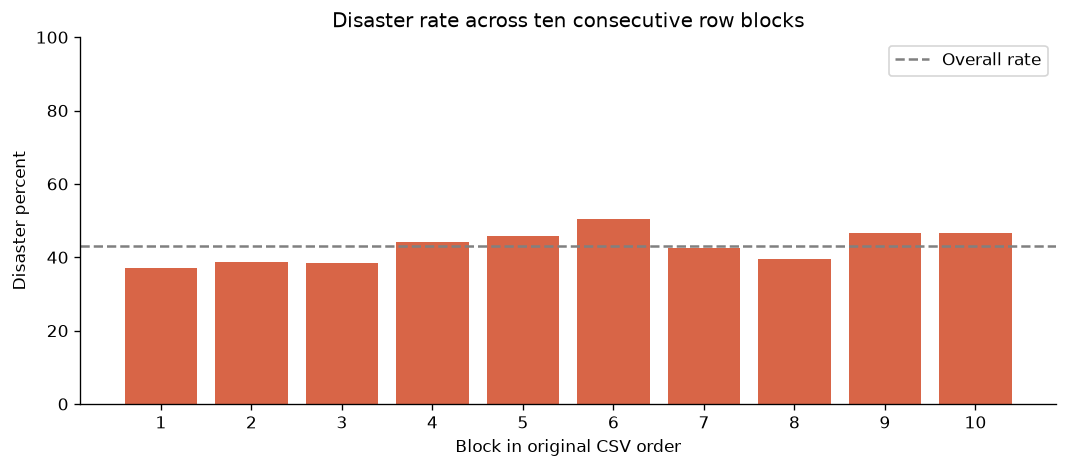

In [8]:
df['row_block'] = np.minimum(np.arange(len(df)) * 10 // len(df), 9) + 1
row_blocks = df.groupby('row_block').agg(count=('id', 'size'), disaster_rate=('target', 'mean'),
                                         keyword_count=('keyword_clean', 'nunique'))
save_table('row_order_blocks', row_blocks, index=True)
display(row_blocks.round(3))
keyword_runs = int(df['keyword_clean'].ne(df['keyword_clean'].shift()).sum())
print(f'Keyword runs in original order: {keyword_runs}; unique keyword values including missing: {df["keyword_clean"].nunique()}')
print('IDs are monotonically increasing:', df['id'].is_monotonic_increasing)
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(row_blocks.index.astype(str), 100*row_blocks['disaster_rate'], color=COLORS[1])
ax.axhline(100*df['target'].mean(), color='grey', linestyle='--', label='Overall rate')
ax.set(title='Disaster rate across ten consecutive row blocks', xlabel='Block in original CSV order', ylabel='Disaster percent', ylim=(0, 100))
ax.legend()
save_figure('06_row_order', fig)

## 7. Findings and next steps

The following report is generated from the measured statistics. It separates
observations from suggested experiments. No models are trained, and no labels
are changed. Read `reports/eda/report.md` for the concise narrative and inspect
the exported conflict rows before choosing a deduplication policy.

In [9]:
exact = duplicate_stats.loc[duplicate_stats['matching_rule'].eq('text')].iloc[0]
conservative = duplicate_stats.loc[duplicate_stats['matching_rule'].eq('normalized_text')].iloc[0]
summary = {
    'source': 'data/raw/train.csv', 'source_sha256': hashlib.sha256((RAW_DATA_DIR/'train.csv').read_bytes()).hexdigest(),
    'rows': len(df), 'columns': original_columns,
    'target_counts': {str(t): int(df['target'].eq(t).sum()) for t in [0, 1]},
    'target_1_fraction': float(df['target'].mean()),
    'missing_counts': {c: int(missing[c].sum()) for c in original_columns},
    'duplicate_id_count': int(df['id'].duplicated().sum()),
    'full_row_duplicates': int(df[original_columns].duplicated().sum()),
    'duplicates': duplicate_stats.to_dict(orient='records'),
    'keyword_unique_non_null': int(df['keyword'].nunique()),
    'location_unique_non_null': int(df['location'].nunique()),
    'keyword_runs': keyword_runs,
    'mean_char_count_by_target': {str(t): float(df.loc[df.target.eq(t), 'char_count'].mean()) for t in [0, 1]},
    'mean_word_count_by_target': {str(t): float(df.loc[df.target.eq(t), 'word_count'].mean()) for t in [0, 1]},
    'max_char_count': int(df['char_count'].max()),
}
(OUT/'summary.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')

def markdown_table(frame):
    # No tabulate dependency; escape pipes and line breaks in raw tweet text.
    clean = frame.copy()
    for c in clean.columns:
        clean[c] = clean[c].map(lambda x: f'{x:.3f}' if isinstance(x, (float, np.floating)) else str(x))
        clean[c] = clean[c].str.replace('|', r'\|', regex=False).str.replace('\n', ' ', regex=False)
    return '\n'.join(['| ' + ' | '.join(map(str, clean.columns)) + ' |',
                      '| ' + ' | '.join(['---']*len(clean.columns)) + ' |'] +
                     ['| ' + ' | '.join(row) + ' |' for row in clean.values.tolist()])

high = eligible.sort_values(['disaster_rate', 'count'], ascending=[False, False]).head(8)
low = eligible.sort_values(['disaster_rate', 'count'], ascending=[True, False]).head(8)
rate_pivot = feature_rates.pivot(index='feature', columns='target', values='present_pct')
report = f'''# train.csv — Exploratory Data Analysis

## Scope and main findings

This report analyzes the supplied **train.csv only**, containing **{len(df):,} tweets and {len(original_columns)} columns**.
Target 1 is interpreted as disaster-related; target 0 as non-disaster.
The source CSV remains unchanged. No model training or test-set analysis is included.

- **Class balance:** {int(df.target.eq(1).sum()):,} disaster tweets ({100*df.target.mean():.2f}%) and {int(df.target.eq(0).sum()):,} non-disaster tweets ({100*df.target.eq(0).mean():.2f}%). The imbalance is moderate; always predicting 0 gives {100*df.target.eq(0).mean():.2f}% accuracy on this sample, not a useful F1 baseline for the positive class.
- **Missing metadata:** keyword is missing in {int(missing.keyword.sum()):,} rows ({100*missing.keyword.mean():.2f}%); location in {int(missing.location.sum()):,} rows ({100*missing.location.mean():.2f}%). Text, ID, and target have no missing entries. There are {df.id.duplicated().sum()} duplicate IDs.
- **Repeated text:** {int(exact.duplicate_groups)} exact-text groups contain {int(exact.rows_in_duplicate_groups)} rows, representing {int(exact.excess_duplicate_rows)} excess rows after keeping one per text. **{int(exact.conflicting_groups)} exact-text groups ({int(exact.rows_in_conflicting_groups)} rows) contain both labels.** Conflicts may reflect annotation noise or missing context and require review.
- **Length:** disaster tweets average {df.loc[df.target.eq(1), 'char_count'].mean():.1f} characters versus {df.loc[df.target.eq(0), 'char_count'].mean():.1f} for non-disaster tweets. Average whitespace word counts are {df.loc[df.target.eq(1), 'word_count'].mean():.2f} and {df.loc[df.target.eq(0), 'word_count'].mean():.2f}, respectively. Raw character lengths include URLs; length alone cannot establish classification quality.
- **Metadata:** {df.keyword.nunique():,} distinct non-null keywords and {df.location.nunique():,} distinct raw locations. Location is sparse, free-form, and high cardinality.

## Data overview

{markdown_table(schema.round(2))}

![Class distribution and missing values](figures/01_overview.png)

## Applied missing-value handling

All {len(train_processed):,} rows are retained in `../../data/processed/train_processed.csv`. Empty and whitespace-only keyword/location values are replaced with `__MISSING__` after trimming. Text, IDs, and labels are unchanged. The location count includes one whitespace-only value, so `isna()` alone undercounts missing locations by one.

{markdown_table(cleaning_audit)}

The marker means that information was not supplied; it is not an inferred keyword or location. Raw-data previews and EDA statistics intentionally retain the original missingness. Open the processed preview in `../../notebooks/01_eda.ipynb` to see the filled values. The three-model feature comparison is available separately in `../baseline/report.md` and `../../notebooks/02_baseline.ipynb` after running the baseline analysis.

## Duplicate and label-quality audit

{markdown_table(duplicate_stats)}

Exact matching uses original text. Conservative matching decodes HTML entities, applies Unicode NFKC, case folding, and whitespace collapse. Template matching also replaces URLs and mentions and is a candidate-review heuristic, not an assertion of semantic identity.

Conservative normalization produces {int(conservative.duplicate_groups)} duplicate groups and {int(conservative.conflicting_groups)} conflicting groups. Inspect `tables/exact_label_conflicts.csv` for the complete exact conflict audit. Identical text can have different keyword/location fields; review full records before deciding whether context explains a conflict. Do not blindly keep the first label or replace labels by majority vote.

## Text features

Percent of tweets within each target class containing each feature:

{markdown_table(rate_pivot.rename(columns={0:'Non-disaster (%)', 1:'Disaster (%)'}).reset_index().round(2))}

URLs occur in {rate_pivot.loc['Contains URL', 1]:.2f}% of disaster tweets and {rate_pivot.loc['Contains URL', 0]:.2f}% of non-disaster tweets. These patterns can reflect source or reporting style. They are descriptive associations and need held-out validation before being treated as useful model features.

![Text lengths and surface feature rates](figures/02_text_features.png)

The longest observed tweet has {df.char_count.max()} raw characters. Choose any future tokenizer length from token-length measurements, rather than assuming character and token lengths are interchangeable. The 90th, 95th, and 99th length percentiles are in `tables/length_quantiles.csv`; longest and shortest examples are also exported.

## Keyword patterns

The following keywords have at least 20 examples. Disaster rate is a fraction from 0 to 1. Counts and 95% Wilson intervals are included because these samples are small. The intervals do not account for duplicate dependence or multiple comparisons.

Highest observed rates:

{markdown_table(high.round(3))}

Lowest observed rates:

{markdown_table(low.round(3))}

![Keyword frequencies and disaster rates](figures/03_keywords.png)

Even explicitly disaster-themed words can appear in jokes, metaphors, entertainment, or unrelated discussion. Keyword identity is not a label substitute. URL-decode keyword values, retain a missing-value marker, and evaluate their incremental contribution alongside text.

## Location patterns

{markdown_table(locations.head(10).round(3))}

![Most frequent raw locations](figures/04_locations.png)

These values can describe the author's profile rather than the event. Do not equate a raw location with verified geography. Keep missing locations as an explicit value instead of dropping one third of the training rows. If location is later encoded using targets, fit that encoding strictly within training folds.

## Vocabulary and repeated phrases

Word and bigram plots use document frequencies after removing URL strings, mentions, and a fixed English stopword list. They show class-normalized prevalence, rather than raw counts from unequal class sizes. At least 20 documents are required for words and 10 for bigrams. This normalization is for EDA, not a mandated modeling pipeline.

![Common words by target](figures/05_words.png)

![Common bigrams by target](figures/05_bigrams.png)

See `tables/words_document_frequencies.csv` and `tables/bigrams_document_frequencies.csv` for exact counts and smoothed log2 prevalence ratios. Positive ratios indicate greater prevalence in disaster tweets; negative ratios indicate greater prevalence in non-disaster tweets. Minimum-frequency filtering and smoothing reduce, but do not eliminate, instability. Repeated messages can amplify particular terms. These patterns do not prove that a phrase generalizes to unseen events.

## Row order and validation

The file contains {keyword_runs} contiguous keyword runs for {df.keyword_clean.nunique()} distinct values including missing. IDs are monotonically increasing: {df.id.is_monotonic_increasing}. Contiguous train/validation slices can therefore produce uneven topic coverage. IDs are identifiers and should be excluded from model inputs; they are not timestamps.

![Target rates across original row order](figures/06_row_order.png)

## Suggested starting workflow

1. Preserve raw text and review the exported label conflicts before applying a cleaning policy. Record decisions rather than silently altering labels.
2. Create a fixed, approximately class-stratified validation split that groups conservative normalized duplicates together (for example, StratifiedGroupKFold). Review template matches separately; replacing URLs and mentions can merge distinct events. For stricter generalization checks, assess event/topic overlap once suitable groups are available. No event/time holdout can be claimed from this file alone.
3. Start with a word/character TF-IDF plus logistic regression baseline. Fit vocabulary, IDF, and any feature selection on training folds only. Compare text alone against text plus keyword; test location separately because it is sparse and noisy.
4. Preserve hashtag words and negation. Test URL/mention normalization as an experiment; avoid irreversible stripping of all punctuation or stopwords, especially if later using a pretrained language model.
5. Report positive-class F1, precision, recall, and a confusion matrix on held-out data. Tune any decision threshold inside training/validation folds, and compare performance under a consistent duplicate policy.

These are proposed experiments; this EDA does not establish model accuracy, causal effects, or population prevalence.

## Reproduce and inspect

- Run `python scripts/eda.py` in the project environment to regenerate figures, tables, metrics, and this report.
- Open `eda_train.ipynb` for the executed cells and outputs; `eda_train.html` is a standalone HTML export of that notebook.
- Full machine-readable metrics: `summary.json`. Source SHA-256: `{summary['source_sha256']}`.
'''
(OUT / 'report.md').write_text(report, encoding='utf-8')
print(f'Wrote report, {len(list(TABLE.glob("*.csv")))} CSV tables, and {len(list(FIG.glob("*.png")))} figures to {OUT.relative_to(ROOT)}')
display(pd.DataFrame({'artifact': ['notebooks/01_eda.ipynb', 'reports/html/01_eda.html', 'reports/eda/report.md', 'reports/eda/summary.json']}))

Wrote report, 16 CSV tables, and 7 figures to reports/eda


,artifact
0,notebooks/01_eda.ipynb
1,reports/html/01_eda.html
2,reports/eda/report.md
3,reports/eda/summary.json
